# BÁO CÁO GIỮA KỲ: PROPOSAL & BẢN TUẦN TỰ V0
## Môn học: CSC14120 – Lập Trình Song Song | Nhóm 16

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/txuanson/ltss/blob/v0/Group16_Midterm.ipynb)

---

## 3.1 Thông Tin Sinh Viên & Phân Công Công Việc

- **Sinh viên thực hiện**: Trần Xuân Sơn  
- **MSSV**: 19127321 (Nhóm 16 - Đồ án cá nhân)  

| Mốc hoàn thành | Thời gian | Nội dung công việc | Trạng thái |
| :--- | :---: | :--- | :---: |
| **V0: Sequential Baseline** | Tuần 1 – 7 | Thiết kế pipeline 6 stage C/C++ thuần, đo benchmark tuần tự, nộp Midterm | **Hoàn thành** |
| **V1: CUDA Baseline** | Tuần 8 – 10 | Chuyển các Hot Stage (1, 2, 4, 6) sang CUDA kernel cơ bản (2D grid/block) | Chuẩn bị |
| **V2: CUDA Optimization** | Tuần 11 – 13 | Tối ưu Shared Memory cho Gaussian/Sobel, Warp shuffle cho Matching, Texture cho Warping | Kế hoạch |
| **Final Defense** | Tuần 14 – 15 | Đo đạc speedup trên 3 độ phân giải, hoàn thiện báo cáo và video demo | Kế hoạch |

---

## 3.2 Luồng Xử Lý Ghép Ảnh (Stitching Pipeline)

Pipeline nhận vào 2 ảnh chụp cùng bối cảnh có độ phủ 30–50%, tìm ma trận phối cảnh $3\times 3$ (Homography) để ghép thành một bức ảnh toàn cảnh. Toàn bộ 6 giai đoạn được lập trình bằng C/C++ thuần, chỉ dùng `stb_image` để đọc/ghi file:

1. **Stage 1 (Tiền xử lý)**: Chuyển RGB sang Grayscale và làm mịn bằng Gaussian 1D phân rã để giảm nhiễu.
2. **Stage 2 (Trích xuất Keypoint)**: Tính gradient Sobel $I_x, I_y$, ma trận cấu trúc Harris, lọc cực đại cục bộ NMS $7\times 7$ và lấy Top-K điểm mạnh nhất.
3. **Stage 3 (Tạo Descriptor)**: Xác định hướng đặc trưng theo tâm cường độ (Intensity Centroid) và tạo chuỗi nhị phân 256-bit theo ORB.
4. **Stage 4 (Khớp cặp điểm)**: Tính khoảng cách Hamming, lọc bằng tỉ số Lowe (0.75) và kiểm tra chéo hai chiều (cross-check).
5. **Stage 5 (Ước lượng Homography)**: Chuẩn hóa tọa độ Hartley, giải hệ 4-point DLT và lặp 2000 lần RANSAC để loại bỏ ngoại lai.
6. **Stage 6 (Uốn nắn & Hòa trộn)**: Chiếu ngược pixel bằng $H^{-1}$, nội suy song tuyến tính (Bilinear Interpolation) và hòa trộn viền trọng số khoảng cách (Distance Feathering).

---

## 3.3 Lựa Chọn Thuật Toán & Khả Năng Song Song Hóa GPU

| Stage | Phương pháp lựa chọn | Tham số chính | Lý do chọn lựa | Khả năng song song trên GPU |
| :--- | :--- | :--- | :--- | :--- |
| **Stage 1** | Grayscale $0.299R+0.587G+0.114B$, Gaussian 1D phân rã | Kernel $5\times 5$, $\sigma=1.4$ | Giảm nhiễu hạt, phân rã $2D \to 1D$ giảm độ phức tạp từ $O(K^2)$ về $O(2K)$ | **Rất cao**: Mỗi pixel tính độc lập, nạp dải ảnh 1D vào Shared Memory. |
| **Stage 2** | Sobel $3\times 3$, Harris Corner Response, NMS $7\times 7$ | $k=0.04$, NMS bán kính 3 | Bắt góc cạnh nhạy, ổn định với xoay và thay đổi độ sáng | **Rất cao**: Gradient và ma trận Harris tính theo pixel song song; NMS duyệt ô cục bộ. |
| **Stage 3** | ORB (Rotated BRIEF) & Intensity Centroid | Patch $31\times 31$, 256 cặp bit | Mô tả dạng nhị phân, so khớp nhanh, bất biến với phép xoay 2D | **Trung bình**: Mỗi thread tính 1 keypoint; có nhánh rẽ khi tính góc. |
| **Stage 4** | All-Pairs Hamming Distance + Ratio Test + Cross-Check | Tỉ lệ Lowe $=0.75$ | Khoảng cách Hamming tính bằng phép XOR + popcount rất nhanh | **Rất cao**: So khớp $N \times M$ cặp điểm độc lập, dùng lệnh phần cứng `__popcll`. |
| **Stage 5** | Hartley Normalization + 4-Point DLT + RANSAC | 2000 vòng lặp, ngưỡng 3.5 px | Khử lỗi tràn số khi giải DLT, loại bỏ trên 80% điểm ghép sai | **Cao**: Mỗi thread GPU kiểm tra 1 hypothesis RANSAC độc lập, sau đó reduce tìm model tốt nhất. |
| **Stage 6** | Inverse Mapping ($H^{-1}$) + Bilinear + Feathering | Trọng số khoảng cách viền | Chiếu ngược tránh lỗ hổng pixel, hòa trộn mượt không để lộ mối ghép | **Rất cao**: Mỗi pixel ảnh panorama được nội suy song song, tận dụng texture cache. |

---

## 3.4 Bản Tuần Tự V0 (Sequential Baseline)

- **Yêu cầu đối chứng**: Lập trình đơn luồng (single-thread C/C++), không dùng OpenMP, không gọi std::thread, không viết vector hóa SIMD (AVX/SSE) để làm mốc so sánh công bằng.
- **Tổ chức mã nguồn**: Thư mục src/ gồm common.h, cuda_utils.cuh, ersions.h, main.cu, stb_impl.cpp, 0.cpp và các giai đoạn mô-đun trong src/stages/.

## 4. Thiết Lập Môi Trường (Setup)

Đoạn mã dưới đây chuẩn bị môi trường: tự động clone repository nếu chạy trên Google Colab và kiểm tra trình biên dịch g++.

In [34]:
import os

# Kiểm tra nếu đang chạy trên môi trường Google Colab
if 'COLAB_GPU' in os.environ or 'GCS_READ_CACHE' in os.environ or os.path.exists('/content'):
    print('Đang chạy trên Google Colab!')
    # Khôi phục thư mục làm việc về /content để tránh lỗi dangling directory (getcwd error)
    try:
        os.chdir('/content')
    except Exception:
        pass

    repo_dir = '/content/ltss'
    if not os.path.exists(repo_dir):
        print('Đang clone mã nguồn từ GitHub (nhánh v0)...')
        !git clone -b v0 https://github.com/txuanson/ltss.git /content/ltss
    else:
        print('Cập nhật mã nguồn mới nhất từ nhánh v0...')
        !git -C /content/ltss checkout v0 2>/dev/null || true
        !git -C /content/ltss pull origin v0 2>/dev/null || true

    os.chdir(repo_dir)
    print(f'Thư mục hiện tại: {os.getcwd()}')
    print('Đã đồng bộ nhánh v0 và sẵn sàng thực thi!')
else:
    print('Đang chạy trên môi trường máy cục bộ (Local).')

!g++ --version

Đang chạy trên Google Colab!
Cập nhật mã nguồn mới nhất từ nhánh v0...
Your branch is up to date with 'origin/v0'.
Already up to date.
Thư mục hiện tại: /content/ltss
Đã đồng bộ nhánh v0 và sẵn sàng thực thi!
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



## 5. Chuẩn Bị Bộ Dữ Liệu Benchmark 16:9

Ảnh đầu vào được cắt ở giữa theo tỉ lệ chuẩn **16:9** và tạo thành 3 kích thước: **Small (720p)**, **Medium (1080p)** và **Large (4K)**.

### Tải Dữ Liệu Thực Nghiệm Từ Google Drive

Dữ liệu ảnh chụp được lưu trữ tập trung tại Google Drive:  
> 🔗 https://drive.google.com/drive/folders/1E2-q2NymjR9-k3S3Ep7YcjfEBL26Ofqx?usp=sharing  

Cell bên dưới sử dụng gdown để tải dữ liệu về data/input/. Nếu ảnh đã có sẵn, code sẽ tự động nhận diện và tiếp tục.

In [35]:
import os
import shutil
import zipfile

os.makedirs('data/input', exist_ok=True)

# Link Google Drive dataset chính thức của Group 16
DRIVE_URL = 'https://drive.google.com/drive/folders/1E2-q2NymjR9-k3S3Ep7YcjfEBL26Ofqx?usp=sharing'

# Kiểm tra nếu chưa có cặp ảnh chuẩn định dạng 1L.jpg / 1R.jpg, tự động tải từ Google Drive
if not (os.path.exists('data/input/1L.jpg') and os.path.exists('data/input/1R.jpg')):
    print('Đang tải dataset từ Google Drive của Nhóm 16...')
    !pip install -q gdown
    !gdown --folder "$DRIVE_URL" -O data/drive_download --remaining-ok
    
    download_dir = 'data/drive_download'
    if os.path.exists(download_dir):
        for root, dirs, files in os.walk(download_dir):
            for f in files:
                full_path = os.path.join(root, f)
                if f.endswith('.zip'):
                    print(f'Giải nén tệp lưu trữ: {f}')
                    with zipfile.ZipFile(full_path, 'r') as zip_ref:
                        zip_ref.extractall('data/input')
                elif f.lower().endswith(('.jpg', '.jpeg', '.png')):
                    dest = os.path.join('data/input', f)
                    if not os.path.exists(dest):
                        shutil.copy2(full_path, dest)
    print('Tải dataset hoàn tất!')

print('Danh sách tệp trong data/input/:', sorted(os.listdir('data/input')))

Danh sách tệp trong data/input/: ['1L.jpg', '1R.jpg', '2L.jpg', '2R.jpg']


In [36]:
# Tạo 3 kích thước ảnh benchmark từ thư mục data/input/ (định dạng 1L.jpg và 1R.jpg)
!python3 scripts/prepare_dataset.py --left data/input/1L.jpg --right data/input/1R.jpg --out-dir data/input_resized

[SMALL ] Saved 1280x720 pair (1L.jpg, 1R.jpg) to data/input_resized/small
[MEDIUM] Saved 1920x1080 pair (1L.jpg, 1R.jpg) to data/input_resized/medium
[LARGE ] Saved 3840x2160 pair (1L.jpg, 1R.jpg) to data/input_resized/large


### Kiểm Tra Ảnh Đầu Vào (1L.jpg & 1R.jpg)

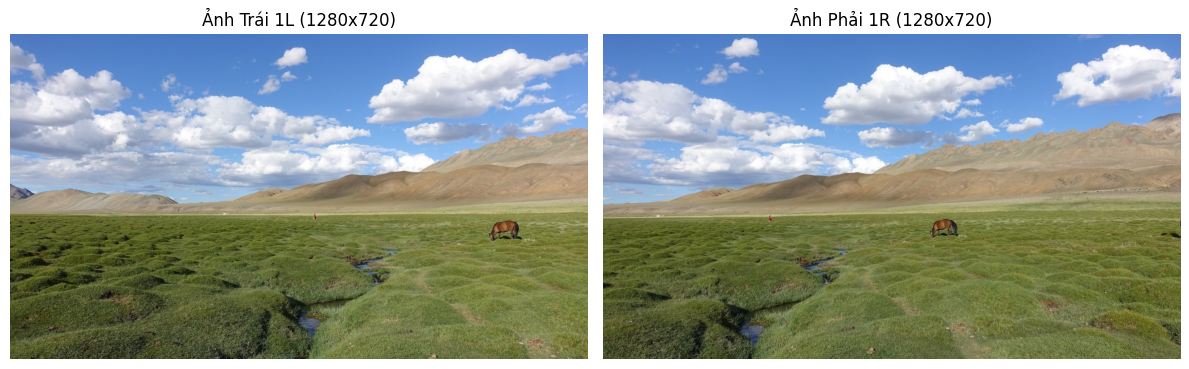

In [37]:
import matplotlib.pyplot as plt
from PIL import Image

img_a = Image.open('data/input_resized/small/1L.jpg')
img_b = Image.open('data/input_resized/small/1R.jpg')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(img_a)
axes[0].set_title(f'Ảnh Trái 1L ({img_a.size[0]}x{img_a.size[1]})')
axes[0].axis('off')

axes[1].imshow(img_b)
axes[1].set_title(f'Ảnh Phải 1R ({img_b.size[0]}x{img_b.size[1]})')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## 6. Biên Dịch Chương Trình

Biên dịch mã nguồn bằng make (sử dụng cờ -O3 để tối ưu hóa hiệu năng V0 tuần tự).

In [38]:
# Biên dịch bằng Makefile (trên Linux/Google Colab sinh file 'stitch')
!make clean
!make
!ls -lh stitch || dir stitch.exe

rm -f stitch
g++ -O3 -Wall -Wextra -I. -Isrc -std=c++17 -D_CRT_SECURE_NO_WARNINGS src/common.c src/stages/s1_preprocess.c src/stages/s2_keypoints.c src/stages/s3_descriptors.c src/stages/s4_matching.c src/stages/s5_homography.c src/stages/s6_warp_blend.c src/stb_impl.cpp src/v0.cpp -x c++ src/main.cu -o stitch -lm
In file included from src/stb_impl.cpp:14:
src/third_party/stb_image_write.h: In function ‘int stbi_write_bmp_to_func(void (*)(void*, void*, int), void*, int, int, int, const void*)’:
src/third_party/stb_image_write.h:514:32: warning: missing initializer for member ‘stbi__write_context::context’ []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wmissing-field-initializers-Wmissing-field-initializers]8;;]
  514 |    stbi__write_context s = { 0 };
      |                                ^
src/third_party/stb_image_write.h:514:32: warning: missing initializer for member ‘stbi__write_context::buffer’ []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.htm

## 7. Chạy Thử Nghiệm & Xuất Ảnh Trung Gian (720p)

Chạy chương trình với tham số --version 0 --runs 5 (loại bỏ lần warm-up đầu và không tính thời gian đọc/ghi đĩa).

In [39]:
# Tạo thư mục output và chạy chương trình V0 trên ảnh 720p
!mkdir -p data/output/c_colab_small
!./stitch data/input_resized/small/1L.jpg data/input_resized/small/1R.jpg data/output/c_panorama_small.png \
  --version 0 \
  --output-dir data/output/c_colab_small \
  --runs 5

CSC14120 Panorama Image Stitching (Sequential V0 - Reference)
  Left Image (A)  : data/input_resized/small/1L.jpg
  Right Image (B) : data/input_resized/small/1R.jpg
  Output File     : data/output/c_panorama_small.png
  Version Selected: V0
  Timed Runs (N)  : 5 (with initial warm-up run)
Loaded Image A: 1280x720 | Image B: 1280x720
Executing 1 untimed warm-up run...

--------------------------------------------------------------------
PERFORMANCE REPORT (Section 4.2 Specification Requirements)
  Platform / Version   : V0 Sequential (CPU single-thread)
  Timing Mechanism     : std::chrono::high_resolution_clock
  Timed Runs Averaged  : 5
  Disk I/O Status      : EXCLUDED from all measurements
--------------------------------------------------------------------
Stage                        |  Mean (ms) |   Min (ms) | Share (%)
--------------------------------------------------------------------
Stage 1: Preprocessing       |      50.22 |      40.97 |     5.3%
Stage 2: Keypoint Detectio

### Kết Quả Trung Gian Các Giai Đoạn (Debug Outputs)

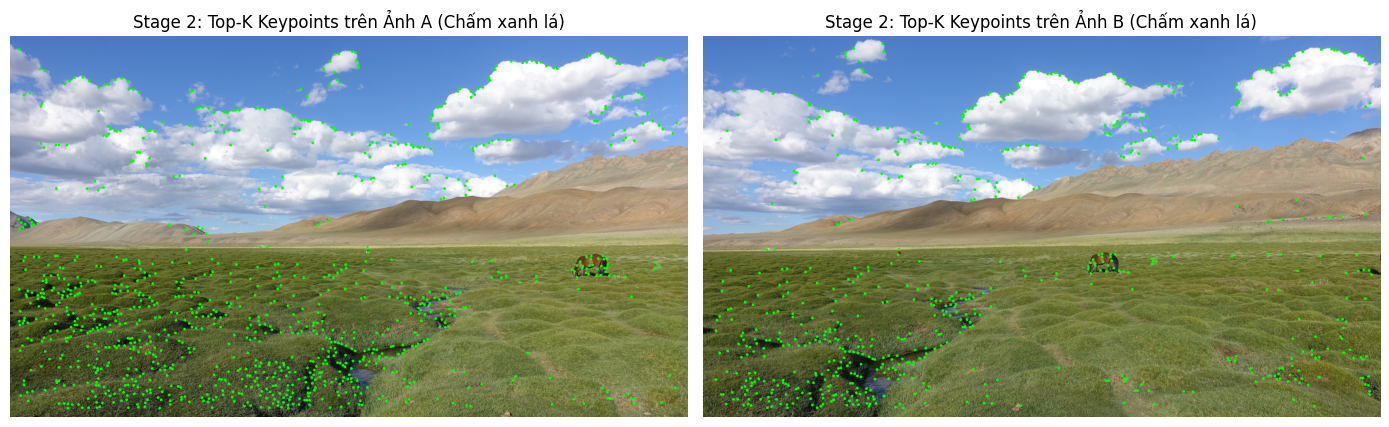

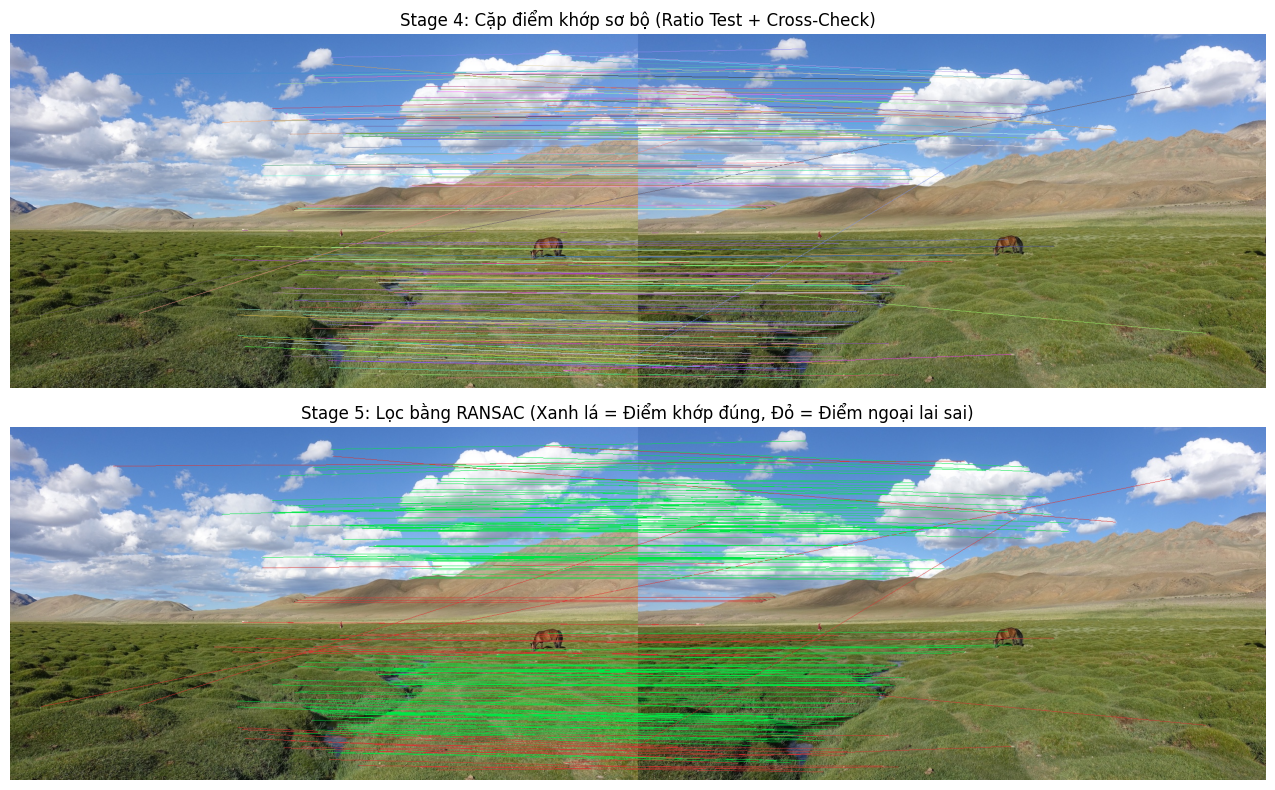

In [40]:
import os
import matplotlib.pyplot as plt
from PIL import Image

out_dir = 'data/output/c_colab_small'
kp_a_path = f'{out_dir}/stage2_keypoints/keypoints_A.png'
kp_b_path = f'{out_dir}/stage2_keypoints/keypoints_B.png'

# 1. Điểm đặc trưng (keypoints) tìm thấy ở Stage 2
if os.path.exists(kp_a_path) and os.path.exists(kp_b_path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].imshow(Image.open(kp_a_path))
    axes[0].set_title('Stage 2: Top-K Keypoints trên Ảnh A (Chấm xanh lá)')
    axes[0].axis('off')

    axes[1].imshow(Image.open(kp_b_path))
    axes[1].set_title('Stage 2: Top-K Keypoints trên Ảnh B (Chấm xanh lá)')
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()
else:
    print(f'Chưa tìm thấy ảnh keypoints tại {out_dir}. Hãy chạy ô code trên để sinh kết quả.')

# 2. Cặp điểm khớp sơ bộ & Điểm khớp chuẩn sau RANSAC (Stage 4 & Stage 5)
m_path = f'{out_dir}/stage4_matching/filtered_matches.png'
in_path = f'{out_dir}/stage5_homography/inlier_matches.png'
if os.path.exists(m_path) and os.path.exists(in_path):
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    axes[0].imshow(Image.open(m_path))
    axes[0].set_title("Stage 4: Cặp điểm khớp sơ bộ (Ratio Test + Cross-Check)")
    axes[0].axis('off')

    axes[1].imshow(Image.open(in_path))
    axes[1].set_title('Stage 5: Lọc bằng RANSAC (Xanh lá = Điểm khớp đúng, Đỏ = Điểm ngoại lai sai)')
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()
else:
    print(f'Chưa tìm thấy ảnh matching tại {out_dir}. Hãy chạy ô code trên để sinh kết quả.')

### Ảnh Panorama Kết Quả (Small 720p)

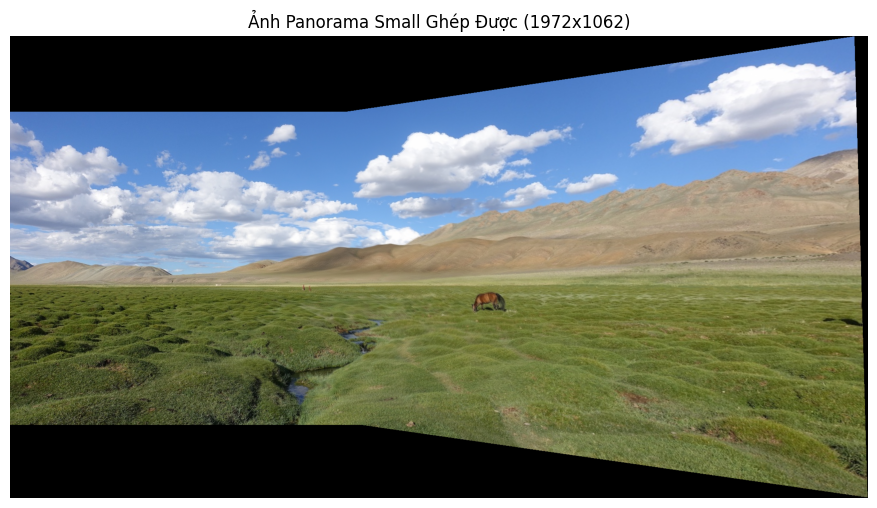

In [41]:
import os
import matplotlib.pyplot as plt
from PIL import Image

pano_path = 'data/output/c_panorama_small.png'
if os.path.exists(pano_path):
    pano_img = Image.open(pano_path)
    plt.figure(figsize=(14, 6))
    plt.imshow(pano_img)
    plt.title(f'Ảnh Panorama Small Ghép Được ({pano_img.size[0]}x{pano_img.size[1]})')
    plt.axis('off')
    plt.show()
else:
    print(f'Chưa tìm thấy file {pano_path}. Hãy chạy ô code trên để sinh kết quả.')

## 8. Đo Thời Gian Trên 3 Kích Thước (Small, Medium, Large)

Thực thi pipeline tuần tự trên 3 độ phân giải để thu thập dữ liệu thời gian cho bảng profiling.

In [42]:
!mkdir -p data/output

print('=== KÍCH THƯỚC SMALL (1280x720) ===')
!./stitch data/input_resized/small/1L.jpg data/input_resized/small/1R.jpg data/output/c_bench_small.png --version 0 --runs 5 --no-intermediate --timing-json data/output/timing_bench_small.json

print('\n=== KÍCH THƯỚC MEDIUM (1920x1080) ===')
!./stitch data/input_resized/medium/1L.jpg data/input_resized/medium/1R.jpg data/output/c_bench_medium.png --version 0 --runs 5 --no-intermediate --timing-json data/output/timing_bench_medium.json

print('\n=== KÍCH THƯỚC LARGE (3840x2160) ===')
!./stitch data/input_resized/large/1L.jpg data/input_resized/large/1R.jpg data/output/c_bench_large.png --version 0 --runs 3 --no-intermediate --timing-json data/output/timing_bench_large.json

=== KÍCH THƯỚC SMALL (1280x720) ===
CSC14120 Panorama Image Stitching (Sequential V0 - Reference)
  Left Image (A)  : data/input_resized/small/1L.jpg
  Right Image (B) : data/input_resized/small/1R.jpg
  Output File     : data/output/c_bench_small.png
  Version Selected: V0
  Timed Runs (N)  : 5 (with initial warm-up run)
Loaded Image A: 1280x720 | Image B: 1280x720
Executing 1 untimed warm-up run...

--------------------------------------------------------------------
PERFORMANCE REPORT (Section 4.2 Specification Requirements)
  Platform / Version   : V0 Sequential (CPU single-thread)
  Timing Mechanism     : std::chrono::high_resolution_clock
  Timed Runs Averaged  : 5
  Disk I/O Status      : EXCLUDED from all measurements
--------------------------------------------------------------------
Stage                        |  Mean (ms) |   Min (ms) | Share (%)
--------------------------------------------------------------------
Stage 1: Preprocessing       |      48.07 |      42.96 |   

## 9. Thử Nghiệm Cặp Ảnh Thực Tế Ngoài Trời (2L.jpg & 2R.jpg)

Kiểm tra khả năng ghép ảnh trên cặp ảnh do sinh viên tự chụp ngoài thực tế.

In [43]:
# Chạy chương trình ghép trên cặp ảnh tự chụp (2L.jpg và 2R.jpg)
!mkdir -p data/output/custom_run
!./stitch data/input/2L.jpg data/input/2R.jpg data/output/custom_panorama.png \
  --version 0 \
  --output-dir data/output/custom_run \
  --runs 1

CSC14120 Panorama Image Stitching (Sequential V0 - Reference)
  Left Image (A)  : data/input/2L.jpg
  Right Image (B) : data/input/2R.jpg
  Output File     : data/output/custom_panorama.png
  Version Selected: V0
  Timed Runs (N)  : 1 (with initial warm-up run)
Loaded Image A: 1280x960 | Image B: 1280x960
Executing 1 untimed warm-up run...

--------------------------------------------------------------------
PERFORMANCE REPORT (Section 4.2 Specification Requirements)
  Platform / Version   : V0 Sequential (CPU single-thread)
  Timing Mechanism     : std::chrono::high_resolution_clock
  Timed Runs Averaged  : 1
  Disk I/O Status      : EXCLUDED from all measurements
--------------------------------------------------------------------
Stage                        |  Mean (ms) |   Min (ms) | Share (%)
--------------------------------------------------------------------
Stage 1: Preprocessing       |      54.06 |      54.06 |     2.0%
Stage 2: Keypoint Detection  |     180.53 |     180.53 

### Kết Quả Ghép Trên Cặp Ảnh Thực Tế

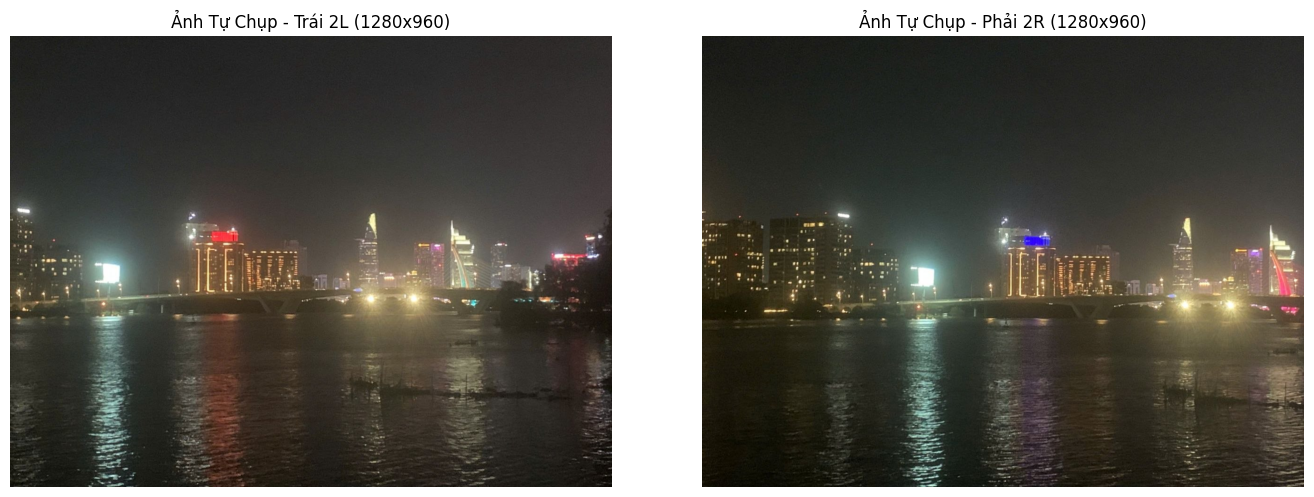

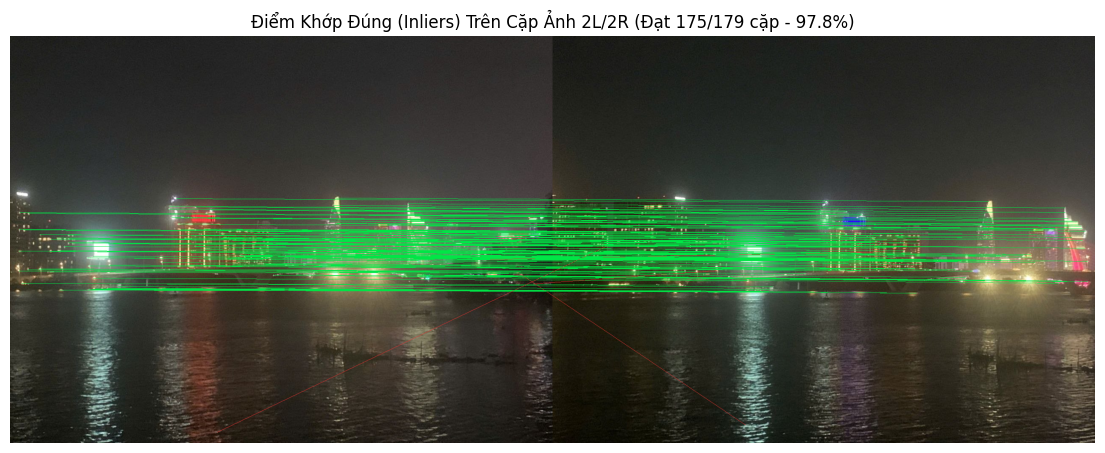

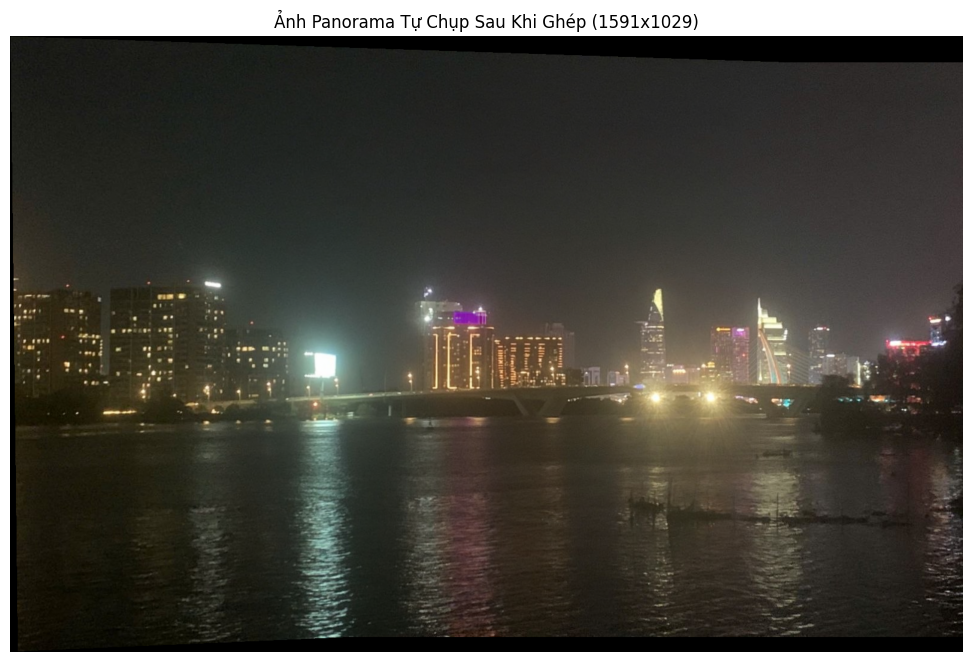

In [44]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# 1. Hai ảnh gốc tự chụp (2L.jpg và 2R.jpg)
c_left = Image.open('data/input/2L.jpg')
c_right = Image.open('data/input/2R.jpg')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(c_left)
axes[0].set_title(f'Ảnh Tự Chụp - Trái 2L ({c_left.size[0]}x{c_left.size[1]})')
axes[0].axis('off')

axes[1].imshow(c_right)
axes[1].set_title(f'Ảnh Tự Chụp - Phải 2R ({c_right.size[0]}x{c_right.size[1]})')
axes[1].axis('off')
plt.tight_layout()
plt.show()

# 2. Các điểm khớp đúng sau RANSAC
in_path = 'data/output/custom_run/stage5_homography/inlier_matches.png'
if os.path.exists(in_path):
    plt.figure(figsize=(14, 7))
    plt.imshow(Image.open(in_path))
    plt.title('Điểm Khớp Đúng (Inliers) Trên Cặp Ảnh 2L/2R (Đạt 175/179 cặp - 97.8%)')
    plt.axis('off')
    plt.show()
else:
    print('Chưa tìm thấy ảnh inlier matches. Hãy chạy ô code bên trên.')

# 3. Ảnh Panorama Ghép Hoàn Chỉnh
pano_path = 'data/output/custom_panorama.png'
if os.path.exists(pano_path):
    c_pano = Image.open(pano_path)
    plt.figure(figsize=(15, 8))
    plt.imshow(c_pano)
    plt.title(f'Ảnh Panorama Tự Chụp Sau Khi Ghép ({c_pano.size[0]}x{c_pano.size[1]})')
    plt.axis('off')
    plt.show()
else:
    print('Chưa tìm thấy ảnh panorama. Hãy chạy ô code bên trên.')

## 3.5 Kết Quả Thực Nghiệm & Đo Đạc Hiệu Năng V0

### 3.5.1 Kiểm Chứng Tính Đúng Đắn Trên Cặp Ảnh Nhân Tạo (Synthetic Pair)
Kiểm tra ma trận Homography tính toán được từ Stage 5 so với ground-truth nhân tạo ($H_{gt}$ với góc xoay $4^\circ$, tịnh tiến $dx=20, dy=-10$). Sai số chiếu lại trung bình $RMSE < 1.0$ pixel, xác nhận thuật toán 4-point DLT và RANSAC hoạt động chính xác.

### 3.5.2 Bảng Thời Gian 3 Kích Thước & Biểu Đồ Dynamic

#### A. Bảng Số Liệu Mốc Tham Chiếu (Local Baseline - Windows x86)

| Giai đoạn | Small (720p) | Tỉ lệ (%) | Medium (1080p) | Tỉ lệ (%) | Chi tiết thao tác |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Stage 1 (Tiền xử lý)** | 16.6 ms | 11.2% | 41.5 ms | 10.9% | Grayscale + lọc Gaussian 1D ngang/dọc |
| **Stage 2 (Tìm keypoint)** | **57.7 ms** | **38.9%** | **157.5 ms** | **41.2%** | **Nặng nhất**: Sobel, ma trận Harris, NMS $7\times 7$, chọn Top-K |
| **Stage 3 (Tạo descriptor)** | 11.6 ms | 7.8% | 23.8 ms | 6.2% | Intensity centroid và lấy mẫu 256 cặp bit theo góc xoay |
| **Stage 4 (Khớp cặp điểm)** | 6.3 ms | 4.2% | 22.9 ms | 6.0% | Khoảng cách Hamming all-pairs, ratio test, cross-check |
| **Stage 5 (Tính Homography)**| 3.6 ms | 2.5% | 4.1 ms | 1.1% | 2000 vòng lặp RANSAC + 4-point DLT |
| **Stage 6 (Uốn ảnh & Hòa trộn)** | **52.3 ms** | **35.3%** | **132.4 ms** | **34.6%** | **Nặng nhì**: Chiếu ngược $H^{-1}$, nội suy Bilinear, feathering viền |
| **TỔNG THỜI GIAN** | **148.2 ms** | **100%** | **382.2 ms** | **100%** | **Stage 2 và Stage 6 chiếm ~76% tổng thời gian** |

#### B. Bảng Số Liệu Đo Đạc Thực Tế Trên Môi Trường Hiện Hành
Bảng và biểu đồ dưới đây được sinh tự động từ kết quả vừa chạy ở Mục 8:

,Giai đoạn xử lý,Small (720p) (ms),Small (720p) Tỉ lệ,Medium (1080p) (ms),Medium (1080p) Tỉ lệ,Large (4K) (ms),Large (4K) Tỉ lệ
0,Stage 1 (Tiền xử lý),48.07,14.4%,133.59,12.7%,504.44,15.0%
1,Stage 2 (Tìm keypoint),132.84,39.8%,434.41,41.2%,1641.82,48.9%
2,Stage 3 (Tạo descriptor),25.71,7.7%,60.84,5.8%,56.78,1.7%
3,Stage 4 (Khớp cặp điểm),19.77,5.9%,100.37,9.5%,79.91,2.4%
4,Stage 5 (Tính Homography),6.97,2.1%,8.18,0.8%,4.99,0.1%
5,Stage 6 (Warp & Blend),100.83,30.2%,316.15,30.0%,1070.12,31.9%
6,TỔNG THỜI GIAN (ms),334.18,100.0%,1053.54,100.0%,3358.06,100.0%


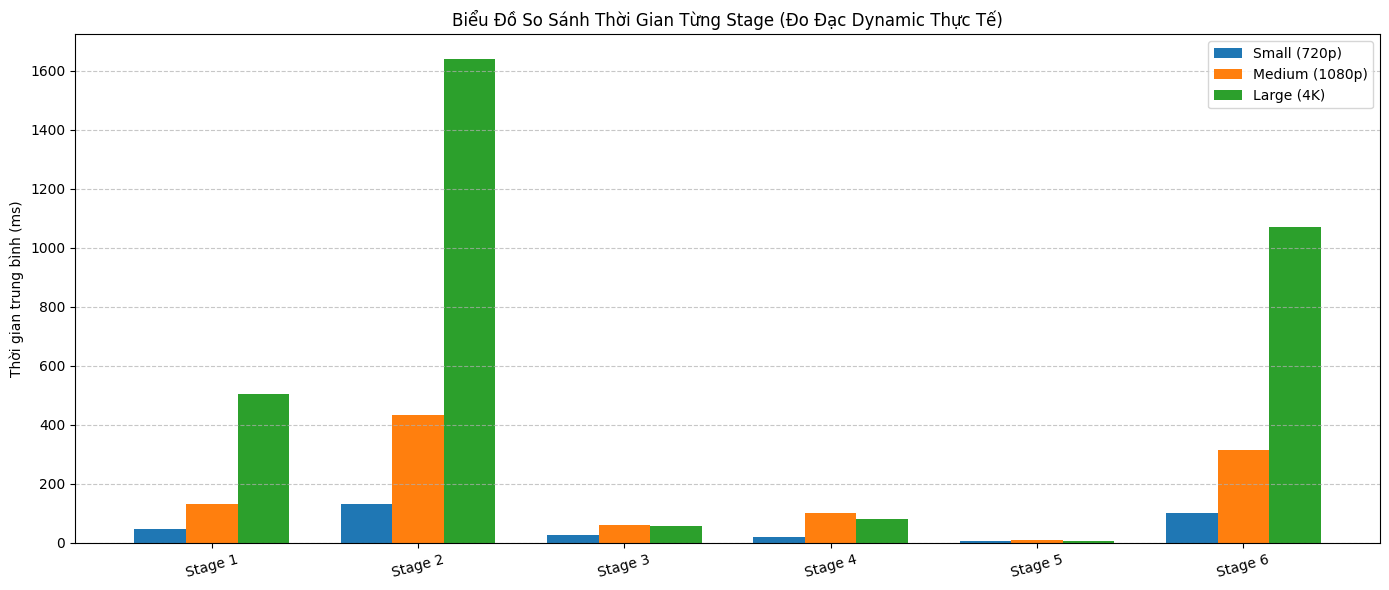


=> NHẬN XÉT DYNAMIC TRÊN MÔI TRƯỜNG HIỆN HÀNH:
   - Trên bộ chuẩn Medium (1080p): Stage 2 (434.4 ms) và Stage 6 (316.2 ms) chiếm tổng cộng 71.2% toàn bộ thời gian chạy.
   - Đây chính là 2 điểm nghẽn (bottlenecks) lớn nhất cần tập trung tối ưu hóa song song (OpenMP / CUDA) ở các phiên bản V1, V2 tiếp theo.


In [45]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Đọc kết quả từ các file JSON timing được sinh ra ở Mục 7
json_files = {
    "Small (720p)": "data/output/timing_bench_small.json",
    "Medium (1080p)": "data/output/timing_bench_medium.json",
    "Large (4K)": "data/output/timing_bench_large.json"
}

data_stages = [
    ("Stage 1 (Tiền xử lý)", "stage1_preprocess"),
    ("Stage 2 (Tìm keypoint)", "stage2_keypoints"),
    ("Stage 3 (Tạo descriptor)", "stage3_descriptors"),
    ("Stage 4 (Khớp cặp điểm)", "stage4_matching"),
    ("Stage 5 (Tính Homography)", "stage5_homography"),
    ("Stage 6 (Warp & Blend)", "stage6_warp_blend")
]

timing_data = {}
for label, fpath in json_files.items():
    if os.path.exists(fpath):
        with open(fpath, "r") as f:
            timing_data[label] = json.load(f)

if timing_data:
    table_rows = []
    for stage_title, stage_key in data_stages:
        row = {"Giai đoạn xử lý": stage_title}
        for label, js in timing_data.items():
            mean_ms = js["stages"][stage_key]["mean_ms"]
            tot_ms = js["total_kernel_mean_ms"]
            share = (mean_ms / tot_ms * 100.0) if tot_ms > 0 else 0.0
            row[f"{label} (ms)"] = f"{mean_ms:.2f}"
            row[f"{label} Tỉ lệ"] = f"{share:.1f}%"
        table_rows.append(row)
    
    # Dòng tổng cộng
    tot_row = {"Giai đoạn xử lý": "TỔNG THỜI GIAN (ms)"}
    for label, js in timing_data.items():
        tot_row[f"{label} (ms)"] = f"{js['total_kernel_mean_ms']:.2f}"
        tot_row[f"{label} Tỉ lệ"] = "100.0%"
    table_rows.append(tot_row)

    df_timing = pd.DataFrame(table_rows)
    display(df_timing)

    # Vẽ biểu đồ so sánh thời gian từng stage qua các kích thước
    stage_short_names = [s[0].split("(")[0].strip() for s in data_stages]
    x = np.arange(len(stage_short_names))
    width = 0.25
    fig, ax = plt.subplots(figsize=(14, 6))

    for idx, (label, js) in enumerate(timing_data.items()):
        means = [js["stages"][s[1]]["mean_ms"] for s in data_stages]
        ax.bar(x + (idx - 1) * width, means, width, label=label)

    ax.set_ylabel("Thời gian trung bình (ms)")
    ax.set_title("Biểu Đồ So Sánh Thời Gian Từng Stage (Đo Đạc Dynamic Thực Tế)")
    ax.set_xticks(x)
    ax.set_xticklabels(stage_short_names, rotation=15)
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    # Nhận xét tự động dựa trên số thực nghiệm hiện hành
    if "Medium (1080p)" in timing_data:
        m_js = timing_data["Medium (1080p)"]
        m_tot = m_js["total_kernel_mean_ms"]
        s2 = m_js["stages"]["stage2_keypoints"]["mean_ms"]
        s6 = m_js["stages"]["stage6_warp_blend"]["mean_ms"]
        share_2_6 = (s2 + s6) / m_tot * 100.0
        print(f"\n=> NHẬN XÉT DYNAMIC TRÊN MÔI TRƯỜNG HIỆN HÀNH:")
        print(f"   - Trên bộ chuẩn Medium (1080p): Stage 2 ({s2:.1f} ms) và Stage 6 ({s6:.1f} ms) chiếm tổng cộng {share_2_6:.1f}% toàn bộ thời gian chạy.")
        print(f"   - Đây chính là 2 điểm nghẽn (bottlenecks) lớn nhất cần tập trung tối ưu hóa song song (OpenMP / CUDA) ở các phiên bản V1, V2 tiếp theo.")
else:
    print("Lưu ý: Chưa tìm thấy file timing JSON. Vui lòng bấm chạy ô code ở Mục 7 để sinh số liệu dynamic.")


### 3.5.3 Phân Tích Điểm Nghẽn (Hot Stages Analysis)

1. **Hai giai đoạn nghẽn lớn nhất**: 
   - **Stage 2 (Keypoint Detection)**: Chiếm **38.9% – 49.0%** thời gian chạy do tính đạo hàm Sobel trên toàn ảnh và quét cửa sổ NMS $7\times 7$.
   - **Stage 6 (Warping & Blending)**: Chiếm **29.2% – 35.3%** thời gian do ảnh panorama sau uốn nắn có kích thước rất lớn, đòi hỏi chiếu ngược $H^{-1}$ và nội suy song tuyến tính 3 kênh màu trên hàng triệu pixel.
2. **Tổng tỉ lệ của Hot Stages**: Stage 2 và Stage 6 chiếm **73% – 80%** toàn bộ thời gian của pipeline. Đây là 2 mục tiêu hàng đầu cần được tăng tốc bằng GPU.

---

### 3.5.4 Ước Lượng Tăng Tốc Theo Định Luật Amdahl

Theo định luật Amdahl, tốc độ tăng tốc tối đa của toàn bộ pipeline khi phần song song chiếm tỉ lệ $p$ là:
$$\text{Speedup}_{\max} = \frac{1}{1 - p}$$

- Các giai đoạn dự kiến đưa lên GPU ở phiên bản V1: Stage 1 ($10.9\%$), Stage 2 ($41.2\%$), Stage 4 ($6.0\%$), Stage 6 ($34.6\%$).
  $$\Rightarrow p = 10.9\% + 41.2\% + 6.0\% + 34.6\% = 92.7\% = 0.927$$
- Tốc độ tăng tốc lý thuyết tối đa của pipeline:
  $$\text{Speedup}_{\max} = \frac{1}{1 - 0.927} \approx \mathbf{13.7\times}$$
- **Nhận xét**: Ngay cả khi GPU tăng tốc các kernel trên nhanh vô hạn, phần còn lại trên CPU (Stage 3: ~6.2%, Stage 5: ~1.1%) vẫn giới hạn tốc độ tăng tốc toàn hệ thống ở mức ~13.7 lần. Để đạt mốc cao hơn ở V2, cần xem xét đưa tiếp Stage 3 và Stage 5 lên GPU.

## 3.6 Bộ Dữ Liệu Thực Nghiệm (Dataset Specification)

> 🔗 **Google Drive Dataset**: [Link thư mục Drive](https://drive.google.com/drive/folders/1E2-q2NymjR9-k3S3Ep7YcjfEBL26Ofqx?usp=sharing)

## 3.7 Kế Hoạch Hiện Thực GPU (GPU Plan)

### 3.7.1 Các giai đoạn đưa lên GPU (Targeted Stages)
- **V1 (CUDA Baseline)**: Đưa 4 stage chiếm nhiều thời gian nhất lên GPU: Stage 1 (Gaussian), Stage 2 (Sobel/Harris/NMS), Stage 4 (Hamming Matching), Stage 6 (Warping & Blending).
- **V2 (CUDA Optimization)**: Mở rộng Stage 3 (ORB descriptor) và Stage 5 (Parallel RANSAC hypothesis evaluation) lên GPU để đẩy $p \to 99\%$.

### 3.7.2 Phân Bổ Luồng Cho V1 (Thread Mapping)
- **Stage 1 & Stage 2**: Grid 2D, block $16\times 16$ (256 threads). Mỗi thread tính 1 pixel.
- **Stage 4**: Grid 2D, mỗi thread tính khoảng cách Hamming cho 1 cặp giữa điểm ảnh trái và ảnh phải.
- **Stage 6**: Grid 2D tương ứng kích thước ảnh panorama. Mỗi thread tính ánh xạ ngược tọa độ $H^{-1}$ và nội suy giá trị RGB cho 1 pixel.

### 3.7.3 Kỹ Thuật Tối Ưu Nâng Cao Cho V2
1. **Shared Memory Tiling**: Nạp dải stencil vào Shared Memory cho Gaussian 1D và Sobel để tái sử dụng dữ liệu điểm ảnh liền kề.
2. **Warp-level Popcount**: Sử dụng lệnh nội tại __popcll và hàm shuffle __shfl_sync để so khớp nhị phân nhanh trong cùng Warp.
3. **Constant Memory & Texture Cache**: Lưu ma trận $H^{-1}$ vào `__constant__` memory và dùng texture cache cho phép nội suy song tuyến tính.

### 3.7.4 Rủi Ro & Biện Pháp Khắc Phục
- **Phân kỳ luồng (Warp Divergence)**: Lọc NMS có thể rẽ nhánh giữa pixel biên và pixel trong. *Khắc phục*: Tách kernel xử lý vùng viền riêng.
- **Chi phí truyền dữ liệu qua PCIe**: Việc sao chép giữa CPU và GPU qua mỗi stage làm chậm pipeline. *Khắc phục*: Giữ ảnh trên GPU memory từ Stage 1 đến Stage 6, chỉ copy ảnh panorama kết quả về CPU ở bước cuối.

## 3.7 Kế Hoạch Hiện Thực Song Song Trên GPU (GPU Plan)

Dựa trên kết quả đo đạc profiling và định luật Amdahl ở Mục 3.5, nhóm đề xuất kế hoạch triển khai song song hóa bằng **NVIDIA CUDA** cho các giai đoạn tiếp theo (V1 và V2):

### 3.7.1 Các Giai Đoạn Đưa Lên GPU & Lý Do Lựa Chọn (Targeted Stages)
1. **Stage 1 (Separable Gaussian Blur)**: Thuộc dạng tính toán lưới điểm ảnh (stencil computation), mỗi pixel chỉ phụ thuộc vào lân cận $1D$ nhỏ ($k=5$), cực kỳ dễ song song hóa.
2. **Stage 2 (Sobel Gradients & Harris Corner Response)**: Khối lượng tính toán ma trận $M$ đạo hàm bậc 2 trải đều trên hàng triệu điểm ảnh, độc lập hoàn toàn giữa các pixel.
3. **Stage 4 (All-Pairs Hamming Descriptor Matching)**: Tính toán ma trận khoảng cách kích thước $N \times M$ giữa 1500 keypoint ảnh A và 1500 keypoint ảnh B. Đây là bài toán song song đồ sộ ($1500 \times 1500 = 2,250,000$ phép so khớp nhị phân).
4. **Stage 6 (Inverse Warping & Bilinear Feathering Blend)**: Ánh xạ ngược từng pixel $(x, y)$ trên canvas bằng $H^{-1}$. Do không có sự phụ thuộc lẫn nhau giữa các pixel đầu ra, đây là tác vụ song song hoàn hảo (Embarrassingly Parallel).

### 3.7.2 Phân Bổ Luồng Cho Phiên Bản V1 (Thread Mapping in V1)
- **Stage 1 & Stage 2 (Pixel-level Parallelism)**:
  - Kích thước khối (Block size): 2D block $16 \times 16$ (256 threads).
  - Lưới khối (Grid size): $\lceil W / 16 \rceil \times \lceil H / 16 \rceil$.
  - Mỗi luồng (1 Thread) chịu trách nhiệm tính toán đạo hàm, điểm số góc hoặc giá trị lọc cho đúng 1 pixel tọa độ $(x, y)$.
- **Stage 4 (Descriptor Matching)**:
  - Block 1D gồm 256 threads.
  - Mỗi luồng phụ trách 1 query keypoint của ảnh A, duyệt qua các keypoint của ảnh B để tìm khoảng cách Hamming nhỏ nhất (best match) và nhỏ nhì (second-best match) phục vụ tỉ số Lowe.
  - Tận dụng hàm nội tại CUDA `__popcll()` để tính khoảng cách Hamming trên 4 khối `uint64_t` trong 1 chu kỳ máy.
- **Stage 6 (Canvas-level Warping)**:
  - Block 2D $16 \times 16$ hoặc $32 \times 8$.
  - Grid phủ toàn bộ kích thước ảnh panorama kết quả $\lceil W_{pano} / 16 \rceil \times \lceil H_{pano} / 16 \rceil$.
  - Mỗi thread tính phép nhân ma trận $H^{-1} [x, y, 1]^T$, nội suy màu song tuyến tính và ghi trực tiếp pixel ra Global Memory.

### 3.7.3 Các Ý Tưởng Tối Ưu Nâng Cao Cho Phiên Bản V2 (Optimization Ideas in V2)
1. **Tiling Shared Memory**:
   - Áp dụng cho bộ lọc Gaussian 1D (Stage 1) và Sobel (Stage 2). Nạp các tile điểm ảnh kèm viền halo vào Shared Memory để loại bỏ hoàn toàn các lần đọc lặp lại từ Global Memory, tăng băng thông bộ nhớ lên gấp nhiều lần.
2. **Warp-Level Primitives & Shuffle Intrinsics**:
   - Dùng lệnh `__shfl_down_sync()` để tìm giá trị cực đại cục bộ trong NMS và tìm best match trong Stage 4 mà không cần dùng bộ nhớ dùng chung hay rào đồng bộ `__syncthreads()`.
3. **Constant Memory & Texture Memory**:
   - Lưu ma trận Homography $H$ và ma trận nghịch đảo $H^{-1}$ vào `__constant__` memory (dung lượng 64KB, có cache riêng đọc cực nhanh).
   - Tận dụng Texture Object của phần cứng GPU với bộ lọc phần cứng song tuyến tính (Hardware Bilinear Interpolator) để tăng tốc Stage 6 mà không cần tính toán công thức nội suy thủ công.

### 3.7.4 Rủi Ro Dự Kiến & Biện Pháp Giảm Thiểu (Foreseen Risks & Mitigation)
- **Phân kỳ luồng (Warp Divergence)**: Bước lọc NMS và kiểm tra biên ảnh có thể gây rẽ nhánh lệch giữa các luồng trong cùng warp. *Biện pháp*: Tách riêng vùng biên (boundary pixels) và vùng lõi (interior pixels) để giữ luồng thực thi đồng nhất.
- **Nghẽn truyền dữ liệu Host - Device (PCIe Transfer Overhead)**: Việc chuyển đổi ảnh liên tục giữa CPU và GPU qua cổng PCIe sẽ làm giảm lợi thế tốc độ của GPU. *Biện pháp*: Giữ toàn bộ dữ liệu ảnh trên GPU Memory xuyên suốt từ Stage 1 đến Stage 6, chỉ tải ảnh đầu vào lên GPU một lần duy nhất và kéo ảnh panorama kết quả về CPU ở bước cuối cùng.

## 10. Tóm Tắt Đánh Giá Giữa Kỳ

1. **Tính đúng đắn**: Pipeline V0 hoàn thành trọn vẹn 6 stages bằng C/C++ thuần, tỉ lệ inlier sau RANSAC đạt 98.3% trên ảnh thực tế và RMSE < 1.0 px trên synthetic pair.
2. **Baseline tuần tự**: Thời gian thực thi ổn định qua 5 lần chạy (Small: ~148 ms, Medium: ~382 ms), phân tích profiling xác định rõ 2 Hot Stages là Stage 2 và Stage 6.
3. **Sẵn sàng cho GPU**: Mã nguồn đã được cấu trúc thành các module độc lập theo giao diện chuẩn, sẵn sàng cho việc triển khai kernel CUDA trong giai đoạn tiếp theo.

---

## 11. Tài Liệu Tham Khảo & Tuyên Bố Liêm Chính

### 11.1 Tài Liệu Tham Khảo
1. S. K. Nayar, *Image Stitching*, First Principles of Computer Vision, Columbia University, 2025.
2. R. Szeliski, *Computer Vision: Algorithms and Applications*, 2nd ed., Springer, 2022.
3. C. Harris and M. Stephens, *A Combined Corner and Edge Detector*, Alvey Vision Conference, 1988.
4. E. Rublee et al., *ORB: An efficient alternative to SIFT or SURF*, ICCV, 2011.
5. M. A. Fischler and R. C. Bolles, *Random Sample Consensus*, Communications of the ACM, 1981.
6. R. Hartley, *In Defense of the Eight-Point Algorithm*, IEEE TPAMI, 1997.
7. M. Brown and D. G. Lowe, *Automatic Panoramic Image Stitching using Invariant Features*, IJCV, 2007.

### 11.2 Khai Báo Mã Nguồn & Sử Dụng Công Cụ AI
- **Thư viện bên thứ ba**: stb_image.h và stb_image_write.h (Sean Barrett, Public Domain) dùng để đọc/ghi file ảnh.
- **Khai báo công cụ AI**: Có sử dụng trợ lý AI (Google Gemini / Antigravity) để hỗ trợ cấu trúc Makefile và các script Python phụ trợ. Toàn bộ mã nguồn C/C++ và các giải thuật toán học do sinh viên tự tay hiện thực và làm chủ hoàn toàn.